# Projeto ML2 — Deteção de sopros cardíacos (CirCor DigiScope)

## 2. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

DATA_DIR = "circor"
CSV_PATH = os.path.join(DATA_DIR, "training_data.csv")
WAV_DIR = os.path.join(DATA_DIR, "training_data")


WINDOW_SEC = 5      # duração de cada janela, em segundos
SR = 4000           # frequência de amostragem das gravações (Hz)

Device: cpu


## 3. Analise Exploratoria

### 3.1 Labels por paciente

In [2]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(942, 23)


,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,High,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,Low,Blowing,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,Low,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN


In [3]:
df.columns.tolist()

['Patient ID',
 'Recording locations:',
 'Age',
 'Sex',
 'Height',
 'Weight',
 'Pregnancy status',
 'Murmur',
 'Murmur locations',
 'Most audible location',
 'Systolic murmur timing',
 'Systolic murmur shape',
 'Systolic murmur grading',
 'Systolic murmur pitch',
 'Systolic murmur quality',
 'Diastolic murmur timing',
 'Diastolic murmur shape',
 'Diastolic murmur grading',
 'Diastolic murmur pitch',
 'Diastolic murmur quality',
 'Outcome',
 'Campaign',
 'Additional ID']

In [4]:
cols = ["Patient ID", "Murmur", "Murmur locations", "Recording locations:", "Most audible location"]
labels = df[cols].copy()
labels.head()

,Patient ID,Murmur,Murmur locations,Recording locations:,Most audible location
0,2530,Absent,NaN,AV+PV+TV+MV,NaN
1,9979,Present,AV+MV+PV+TV,AV+PV+TV+MV,TV
2,9983,Unknown,NaN,AV+PV+TV+MV,NaN
3,13918,Present,TV,AV+PV+TV+MV,TV
4,14241,Present,AV+MV+PV+TV,AV+PV+TV+MV,PV


In [5]:
print(labels["Murmur"].value_counts())
print(labels["Murmur"].value_counts(normalize=True).round(3))

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64
Murmur
Absent     0.738
Present    0.190
Unknown    0.072
Name: proportion, dtype: float64


### Distribuição das classes (Murmur)

O dataset público tem **942 pacientes**, distribuídos da seguinte forma:

| Classe  | Pacientes | %      |
|---------|----------:|-------:|
| Absent  | 695       | 73,8 % |
| Present | 179       | 19,0 % |
| Unknown | 68        | 7,2 %  |

**Observações:**

1. **Forte desequilíbrio entre classes.** Um modelo que previsse sempre "Absent" teria uma accuracy de **73,8 %** sem detetar nenhum sopro. Por isso, a accuracy **não é uma métrica adequada** para avaliar os modelos.

2. **Métricas a usar:**
   - **Matriz de confusão**, para ver onde cada classe é confundida;
   - **Recall por classe**, com especial atenção ao recall de Present;
   - **F1 macro / balanced accuracy**, que dão o mesmo peso a todas as classes.

3. **Contexto clínico:** falhar um Present (falso negativo) é mais grave do que um falso alarme, que apenas leva a exames adicionais. O recall da classe Present é, por isso, prioritário.

4. **Implicações para o treino:** será necessário compensar o desequilíbrio, por exemplo com class weights na função de perda, oversampling ou data augmentation das classes minoritárias.

5. **A classe Unknown é a mais difícil:** tem poucos exemplos (68) e corresponde a casos em que o próprio especialista não conseguiu decidir. Esperam-se resultados mais fracos nesta classe.

### 3.2 Tabela de gravações

Cada paciente tem várias gravações (uma por válvula, por vezes repetidas), mas a label Murmur é atribuída ao paciente. Para treinar os modelos é preciso uma tabela com **uma linha por gravação**, construída a partir dos nomes dos ficheiros `.wav` (formato `IDPACIENTE_VÁLVULA[_n].wav`) e associada às labels do paciente.

In [6]:
#Quantos ficheiros .wav tem o dataset

import glob
wav_files = sorted(glob.glob(os.path.join(WAV_DIR, "*.wav")))
len(wav_files)

3163

In [7]:
#Para cada ficheiro, extrair o ID e a válvula

nome = os.path.basename(wav_files[0])   # tira a pasta, fica só "1234_AV.wav"
partes = nome.replace(".wav", "").split("_")
partes

['13918', 'AV']

In [8]:
linhas = []

for path in wav_files:
    nome = os.path.basename(path)
    partes = nome.replace(".wav", "").split("_")

    patient_id = int(partes[0])
    location = partes[1]

    linhas.append({
        "path": path,
        "patient_id": patient_id,
        "location": location,
    })

rec = pd.DataFrame(linhas)
print(rec.shape)
rec.head()

(3163, 3)


,path,patient_id,location
0,circor/training_data/13918_AV.wav,13918,AV
1,circor/training_data/13918_MV.wav,13918,MV
2,circor/training_data/13918_PV.wav,13918,PV
3,circor/training_data/13918_TV.wav,13918,TV
4,circor/training_data/14241_AV.wav,14241,AV


In [9]:
rec = rec.merge(labels, left_on="patient_id", right_on="Patient ID")
print(rec.shape)
rec.head()

(3163, 8)


,path,patient_id,location,Patient ID,Murmur,Murmur locations,Recording locations:,Most audible location
0,circor/training_data/13918_AV.wav,13918,AV,13918,Present,TV,AV+PV+TV+MV,TV
1,circor/training_data/13918_MV.wav,13918,MV,13918,Present,TV,AV+PV+TV+MV,TV
2,circor/training_data/13918_PV.wav,13918,PV,13918,Present,TV,AV+PV+TV+MV,TV
3,circor/training_data/13918_TV.wav,13918,TV,13918,Present,TV,AV+PV+TV+MV,TV
4,circor/training_data/14241_AV.wav,14241,AV,14241,Present,AV+MV+PV+TV,AV+PV+TV+MV,PV


In [10]:
rec["most_audible"] = rec["location"] == rec["Most audible location"]

def murmur_here(row):
    if pd.isna(row["Murmur locations"]):
        return False
    lista = row["Murmur locations"].split("+")
    return row["location"] in lista

rec["murmur_here"] = rec.apply(murmur_here, axis=1)

In [11]:
rec[rec["patient_id"] == 13918][["location", "Murmur", "Murmur locations", "murmur_here", "most_audible"]]

,location,Murmur,Murmur locations,murmur_here,most_audible
0,AV,Present,TV,False,False
1,MV,Present,TV,False,False
2,PV,Present,TV,False,False
3,TV,Present,TV,True,True


In [12]:
pd.crosstab(rec["Murmur"], rec["murmur_here"])

murmur_here,False,True
Murmur,,
Absent,2391,0
Present,117,499
Unknown,156,0


**Decisão — label por gravação (`label_rec`):** as 117 gravações de pacientes Present em que o sopro não foi ouvido (válvula fora de `Murmur locations`) passam a *Absent* para efeitos de treino. A coluna `Murmur` original mantém-se para a avaliação final, que é feita por paciente. Esta decisão será comparada mais tarde com a alternativa de excluir estas gravações do treino.

In [13]:
def label_rec(row):
    if row["Murmur"] == "Present" and not row["murmur_here"]:
        return "Absent"
    return row["Murmur"]

rec["label_rec"] = rec.apply(label_rec, axis=1)
rec["label_rec"].value_counts()

label_rec
Absent     2508
Present     499
Unknown     156
Name: count, dtype: int64

#### Gravações por paciente e por válvula

Como a label é atribuída ao paciente e o treino é feito por gravação, importa saber quantas gravações tem cada paciente: pacientes com mais gravações têm mais peso no treino. Verifica-se também a distribuição por válvula e o número de gravações repetidas da mesma válvula.

In [14]:
print("Nº de gravações por paciente:")
print(rec.groupby("patient_id").size().value_counts().sort_index())

print("\nNº de gravações por válvula:")
print(rec["location"].value_counts())

n_rep = rec.duplicated(subset=["patient_id", "location"], keep=False).sum()
print("\nGravações que repetem a válvula do mesmo paciente:", n_rep)

Nº de gravações por paciente:
1     62
2    156
3    123
4    588
5     10
6      3
Name: count, dtype: int64

Nº de gravações por válvula:
location
MV     861
AV     800
PV     766
TV     732
Phc      4
Name: count, dtype: int64

Gravações que repetem a válvula do mesmo paciente: 43


**Observações:**
- A maioria dos pacientes (588 de 942, 62 %) tem 4 gravações, uma por válvula. 341 pacientes (36 %) têm menos de 4 gravações e apenas 13 têm mais (5 ou 6), devido a gravações repetidas.
- As quatro válvulas principais estão representadas de forma equilibrada: MV (861), AV (800), PV (766) e TV (732). A localização Phc (outra localização) é muito rara, com apenas 4 gravações.
- Existem 43 gravações que repetem a válvula do mesmo paciente (ficheiros `_1`, `_2`). São tratadas como gravações independentes, mas ficam sempre no mesmo conjunto (treino, validação ou teste), porque o split é feito por paciente.
- Os 62 pacientes com uma única gravação são um caso particular na avaliação por paciente: se o sopro estiver numa válvula que não foi gravada, nenhum modelo o consegue detetar a partir dos dados disponíveis. Este ponto será retomado na discussão dos resultados.

### 3.3 Duração das gravações

In [15]:
import soundfile as sf

info = sf.info(rec["path"].iloc[0])
print(info)

circor/training_data/13918_AV.wav
samplerate: 4000 Hz
channels: 1
duration: 10.288 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


In [16]:
rec["duration"] = rec["path"].apply(lambda p: sf.info(p).duration)

rec[["path", "label_rec", "duration"]].head()

,path,label_rec,duration
0,circor/training_data/13918_AV.wav,Absent,10.288
1,circor/training_data/13918_MV.wav,Absent,28.784
2,circor/training_data/13918_PV.wav,Absent,9.392
3,circor/training_data/13918_TV.wav,Present,6.592
4,circor/training_data/14241_AV.wav,Present,20.480


In [17]:
rec["duration"].describe()

count    3163.000000
mean       22.870301
std         7.282948
min         5.152000
25%        19.056000
50%        21.456000
75%        29.392000
max        64.512000
Name: duration, dtype: float64

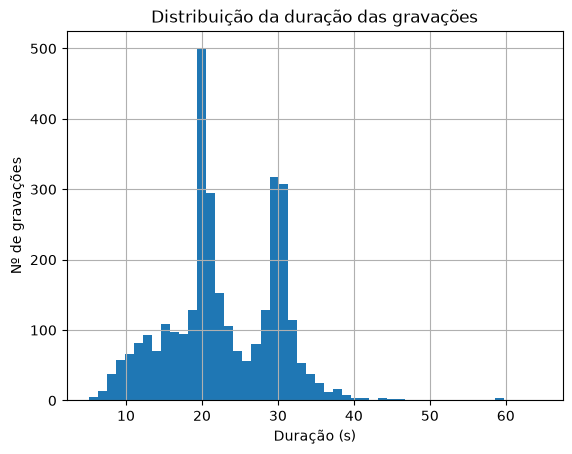

In [18]:
rec["duration"].hist(bins=50)
plt.xlabel("Duração (s)")
plt.ylabel("Nº de gravações")
plt.title("Distribuição da duração das gravações")
plt.show()

In [19]:
rec.groupby("label_rec")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
label_rec,,,,,,,,
Absent,2508.0,22.924904,7.129434,5.152,19.056,21.552,29.464,58.752
Present,499.0,22.741355,8.097988,6.384,18.920,21.248,28.944,64.512
Unknown,156.0,22.404923,6.993879,7.552,19.172,21.072,27.208,43.888


**Observações sobre a duração:**
- As durações variam entre 5,2 s e 64,5 s (mediana 21,5 s), com dois picos claros à volta dos 20 s e dos 30 s, o que sugere durações-padrão no protocolo de gravação.
- A distribuição da duração é praticamente igual nas três classes, por isso a duração não é um indicador da classe.
- Como os modelos exigem inputs de tamanho fixo, as gravações serão divididas em janelas. Com uma duração mínima de ~5 s, uma janela de 4 a 5 s cabe em todas as gravações e contém vários ciclos cardíacos completos.

### 3.4 Visualização dos sons

In [20]:
ex_present = rec[(rec["label_rec"] == "Present") & (rec["most_audible"])].iloc[0]
ex_absent = rec[rec["label_rec"] == "Absent"].iloc[0]

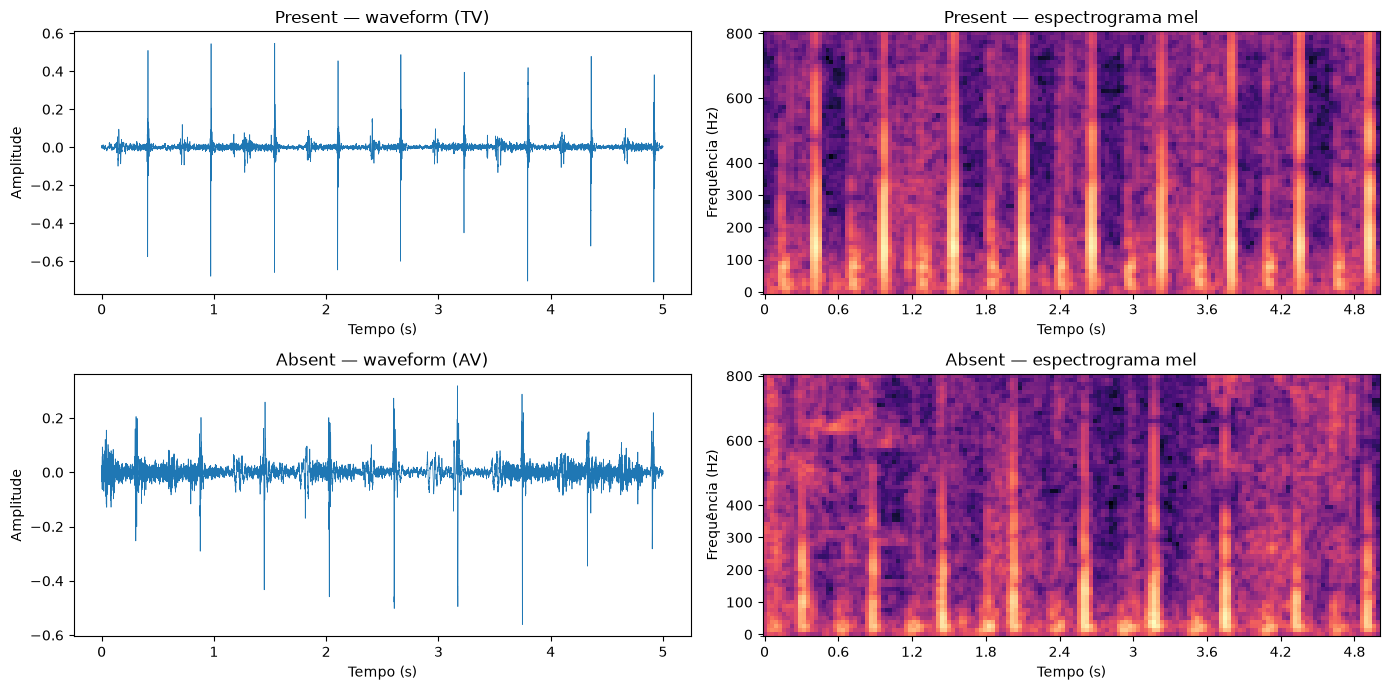

In [21]:
import librosa
import librosa.display

def plot_example(row, axes, titulo):
    # 1. carregar só os primeiros WINDOW_SEC segundos
    y, sr = librosa.load(row["path"], sr=None, duration=WINDOW_SEC)

    # 2. waveform (esquerda)
    t = np.arange(len(y)) / sr
    axes[0].plot(t, y, linewidth=0.5)
    axes[0].set_title(f"{titulo} — waveform ({row['location']})")
    axes[0].set_xlabel("Tempo (s)")
    axes[0].set_ylabel("Amplitude")

    # 3. espectrograma mel (direita)
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=512, hop_length=128, n_mels=64, fmax=800)
    S_db = librosa.power_to_db(S, ref=np.max)
    librosa.display.specshow(S_db, sr=sr, hop_length=128, x_axis="time", y_axis="mel", fmax=800, ax=axes[1])
    axes[1].set_yticks([0, 100, 200, 300, 400, 600, 800])
    axes[1].set_ylabel("Frequência (Hz)")
    axes[1].set_xlabel("Tempo (s)")
    axes[1].set_title(f"{titulo} — espectrograma mel")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_example(ex_present, axes[0], "Present")
plot_example(ex_absent, axes[1], "Absent")
plt.tight_layout()
plt.show()

**Espectrograma mel**

O espectrograma representa a energia do som em cada frequência ao longo do tempo: o eixo x é o tempo, o eixo y a frequência e a cor a energia. É obtido dividindo o sinal em janelas curtas (512 amostras ≈ 0,13 s, com avanço de 128 amostras) e calculando o espectro de cada uma.

Na escala mel, as frequências são agrupadas em bandas (64, até 800 Hz) com maior resolução nas frequências baixas, imitando a perceção auditiva humana. Isto é adequado a sons cardíacos, cuja informação relevante está abaixo de ~500 Hz (S1 e S2 abaixo de ~150 Hz; sopros até ~500 Hz). A energia é convertida para decibéis, para que componentes mais fracas, como os sopros, não fiquem escondidas pelos S1 e S2.

O espectrograma mel transforma o som numa imagem 2D, o que o torna um input natural para uma CNN.

**Observações dos exemplos:**
- Os S1 e S2 aparecem como riscas verticais curtas e intensas, repetidas a cada batimento.
- O exemplo Absent tem mais ruído de fundo do que o exemplo Present, o que mostra que "som pouco limpo" não implica a presença de sopro.
- As amplitudes variam muito entre gravações, o que justifica normalizar cada gravação no pré-processamento.

Para ilustrar claramente o padrão de um sopro, compara-se ainda um caso de sopro forte (grau III/VI, holossistólico), na localização onde é mais audível, com os dois exemplos anteriores.

In [22]:
fortes = df[(df["Systolic murmur grading"] == "III/VI") & (df["Systolic murmur timing"] == "Holosystolic")]
print(len(fortes))
fortes[["Patient ID", "Most audible location"]].head()

33


,Patient ID,Most audible location
1,9979,TV
21,44514,PV
33,49574,TV
43,49628,TV
68,49821,MV


In [23]:
pid = fortes["Patient ID"].iloc[0]
ex_forte = rec[(rec["patient_id"] == pid) & (rec["most_audible"])].iloc[0]

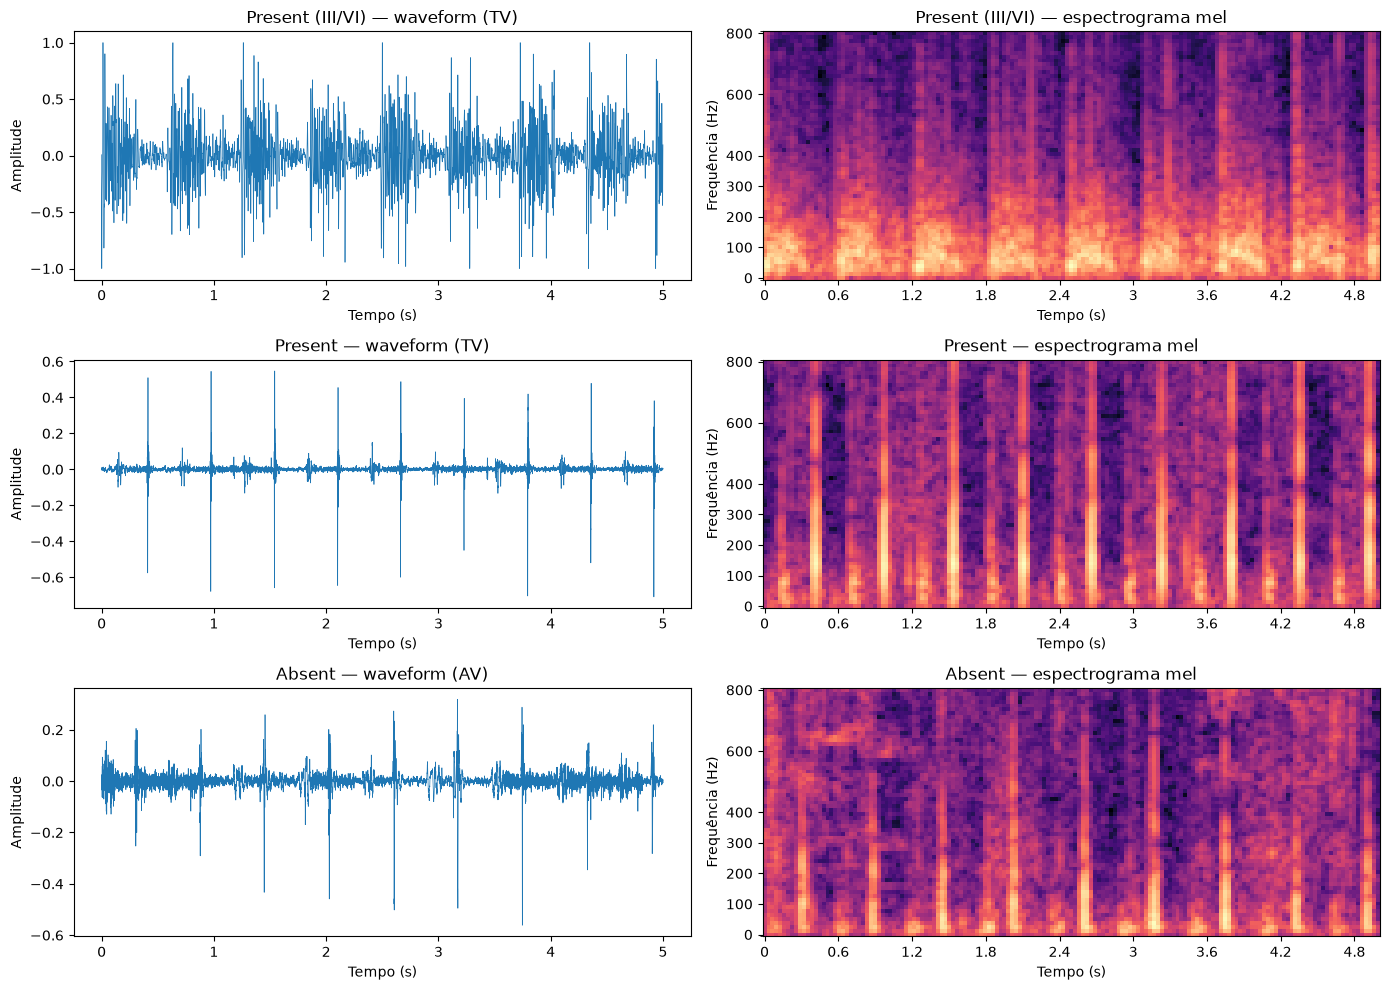

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
plot_example(ex_forte, axes[0], "Present (III/VI)")
plot_example(ex_present, axes[1], "Present")
plot_example(ex_absent, axes[2], "Absent")
plt.tight_layout()
plt.show()

**Observações:**
- No caso de sopro forte (III/VI, holossistólico), o sopro aparece como blocos de energia contínua entre ~0 e 300 Hz que preenchem o intervalo entre batimentos e se repetem em todos os ciclos. Ao contrário do ruído do exemplo Absent, que está espalhado e sem ritmo, o sopro está concentrado nas frequências baixas e sincronizado com o ciclo cardíaco.
- A energia do sopro concentra-se abaixo de ~400 Hz, o que justifica um filtro passa-baixo nessa zona e o limite de 800 Hz no espectrograma mel.

#### Sobreposição da segmentação do ciclo cardíaco

Cada gravação tem um ficheiro `.tsv` com a segmentação do ciclo cardíaco, feita por algoritmos e validada por especialistas. Cada linha indica o início e o fim (em segundos) de uma fase:

| Código | Fase |
|---|---|
| 1 | S1 (fecho das válvulas mitral e tricúspide, início da sístole) |
| 2 | Sístole (contração do coração) |
| 3 | S2 (fecho das válvulas aórtica e pulmonar, início da diástole) |
| 4 | Diástole (relaxamento do coração) |
| 0 | Sem anotação |

**Porquê sobrepor a segmentação?**

Um sopro distingue-se do ruído por estar sincronizado com o ciclo cardíaco: aparece sempre na mesma fase (por exemplo, na sístole) e repete-se em todos os batimentos. Ao marcar as fases sobre os gráficos é possível verificar se a energia observada no caso de sopro forte cai, de facto, na sístole, e confirmar que os S1 e S2 correspondem às riscas verticais do espectrograma.

Esta verificação ajuda a validar a interpretação dos espectrogramas e mostra que a informação temporal (em que fase do ciclo surge a energia) é relevante. Isto favorece modelos que preservam a estrutura temporal do sinal, como a CNN sobre espectrogramas ou a RNN.

In [25]:
def load_segments(row):
    tsv_path = row["path"].replace(".wav", ".tsv")
    seg = pd.read_csv(tsv_path, sep="\t", header=None, names=["start", "end", "state"])
    return seg[seg["start"] < WINDOW_SEC]    # só as fases dentro da janela de 5 s

load_segments(ex_forte).head(10)

,start,end,state
0,0.000000,0.540500,0
1,0.540500,0.700435,1
2,0.700435,0.860337,2
3,0.860337,0.963066,3
4,0.963066,1.173507,4
5,1.173507,1.420337,1
6,1.420337,1.500337,2
7,1.500337,1.620337,3
8,1.620337,1.789679,4
9,1.789679,2.020337,1


In [26]:
CORES = {2: ("tab:red", "Sístole"), 4: ("tab:blue", "Diástole")}

def add_segments(ax, row):
    seg = load_segments(row)
    for _, s in seg.iterrows():
        if s["state"] in CORES:
            cor, _ = CORES[s["state"]]
            ax.axvspan(s["start"], min(s["end"], WINDOW_SEC), color=cor, alpha=0.2)

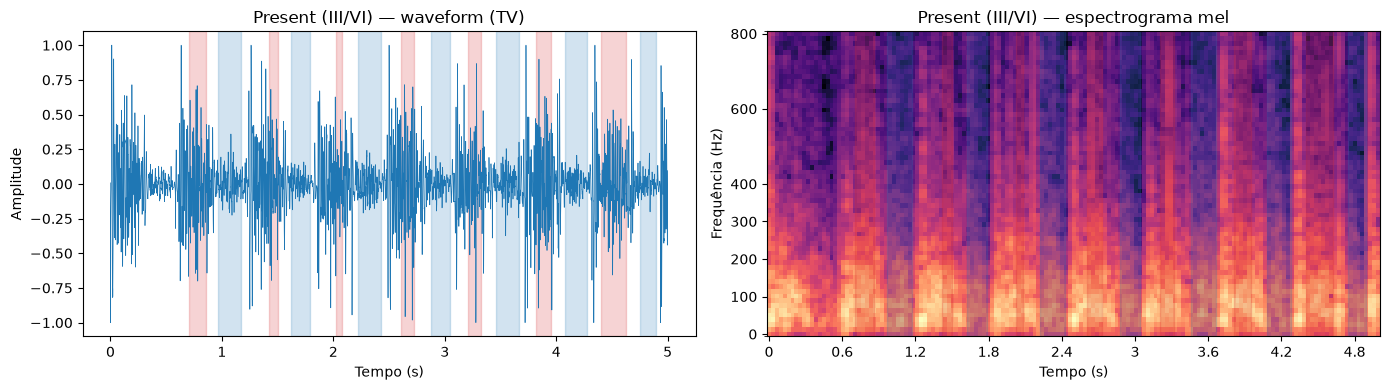

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_example(ex_forte, axes, "Present (III/VI)")
add_segments(axes[0], ex_forte)
add_segments(axes[1], ex_forte)
plt.tight_layout()
plt.show()

**Observação:** a energia do sopro concentra-se na sístole (faixas vermelhas) e nos S1 que a antecedem, repetindo-se em todos os ciclos, enquanto a diástole (faixas azuis) é praticamente silenciosa. Isto confirma que o sopro deste paciente é sistólico, de acordo com a anotação clínica (holossistólico), e que o que distingue um sopro do ruído é a sua sincronização com o ciclo cardíaco. Nota-se ainda que o início da gravação (~0,7 s) não tem segmentação (código 0), embora contenha o mesmo padrão.

### 3.5 Resumo da análise exploratória

**Dados**
- O dataset público tem 942 pacientes e 3163 gravações, amostradas a 4000 Hz.
- A label Murmur é atribuída ao paciente: Absent (73,8 %), Present (19,0 %) e Unknown (7,2 %).

**Desequilíbrio entre classes**
- Um modelo que previsse sempre Absent teria 73,8 % de accuracy sem detetar nenhum sopro. A avaliação será feita com matriz de confusão, recall por classe e F1 macro / balanced accuracy, com especial atenção ao recall de Present.
- Será necessário compensar o desequilíbrio no treino (class weights, oversampling ou data augmentation).

**Label por gravação**
- 117 das 616 gravações de pacientes Present (19 %) foram feitas em válvulas onde o sopro não foi ouvido. Para o treino, estas gravações passam a Absent (coluna `label_rec`). A avaliação final é feita por paciente, com a label original.
- Ao nível das gravações, o desequilíbrio aumenta: 2508 Absent, 499 Present e 156 Unknown.

**Duração**
- As gravações variam entre 5,2 s e 64,5 s (mediana 21,5 s), com dois picos à volta dos 20 s e dos 30 s. A duração é semelhante nas três classes, por isso não é indicadora da classe.
- Os modelos exigem inputs de tamanho fixo: as gravações serão divididas em janelas de 5 s, que cabem em todas as gravações e contêm vários ciclos cardíacos.

**Características do sinal**
- Os S1 e S2 aparecem como eventos curtos e intensos; um sopro aparece como energia contínua, concentrada abaixo de ~400 Hz e sincronizada com o ciclo cardíaco (no exemplo analisado, na sístole).
- Muitas gravações têm ruído de fundo (fala, choro, fricção), que pode confundir-se com um sopro. O que distingue os dois é a sincronização com o ciclo cardíaco, o que favorece modelos que preservam a estrutura temporal.
- As amplitudes variam muito entre gravações (incluindo possível saturação), independentemente da classe.

**Decisões para o pré-processamento**
1. Divisão treino / validação / teste por paciente, para evitar data leakage.
2. Filtro passa-banda (~25–400 Hz) para remover ruído fora da banda útil.
3. Normalização da amplitude de cada gravação.
4. Divisão em janelas de 5 s.
5. Espectrograma mel (até 800 Hz) como representação de input para a CNN.

## 4. Pré-processamento
### 4.1 Divisão treino / validação / teste

Os dados são divididos em treino (70 %), validação (15 %) e teste (15 %):
- **Treino:** usado para ajustar os pesos dos modelos.
- **Validação:** usado para tomar decisões durante o desenvolvimento (escolha de hiperparâmetros, pré-processamento e arquitetura, deteção de overfitting e early stopping). Nunca é usado para ajustar os pesos.
- **Teste:** usado apenas uma vez, na avaliação final, para obter uma estimativa não enviesada do desempenho.

A divisão é feita **por paciente**, para que todas as gravações do mesmo paciente fiquem no mesmo conjunto e o modelo nunca seja avaliado em pacientes que viu durante o treino (evitando data leakage). É também estratificada pela label Murmur, para manter a proporção das três classes em cada conjunto, o que é importante sobretudo para a classe Unknown, que tem poucos pacientes.

In [28]:
from sklearn.model_selection import train_test_split

SEED = 42

# 1ª divisão: 70 % treino, 30 % resto
train_ids, rest_ids = train_test_split(
    labels["Patient ID"],
    test_size=0.30,
    stratify=labels["Murmur"],
    random_state=SEED,
)

# 2ª divisão: o resto ao meio → 15 % validação, 15 % teste
rest_labels = labels.set_index("Patient ID").loc[rest_ids, "Murmur"]
val_ids, test_ids = train_test_split(
    rest_ids,
    test_size=0.50,
    stratify=rest_labels,
    random_state=SEED,
)

print(len(train_ids), len(val_ids), len(test_ids))

659 141 142


In [29]:
def get_split(pid):
    if pid in set_train:
        return "train"
    if pid in set_val:
        return "val"
    return "test"

set_train, set_val = set(train_ids), set(val_ids)
rec["split"] = rec["patient_id"].apply(get_split)

In [30]:
# Nenhum paciente pode estar em dois conjuntos
assert not (set(train_ids) & set(val_ids))
assert not (set(train_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))

# Proporção das classes por conjunto (por paciente)
pac = rec.drop_duplicates("patient_id")
print(pd.crosstab(pac["split"], pac["Murmur"], normalize="index").round(3))

# Nº de gravações por conjunto e classe (label usada no treino)
print(pd.crosstab(rec["split"], rec["label_rec"]))

Murmur  Absent  Present  Unknown
split                           
test     0.739    0.190    0.070
train    0.737    0.190    0.073
val      0.738    0.191    0.071
label_rec  Absent  Present  Unknown
split                              
test          384       77       21
train        1747      348      112
val           377       74       23


In [31]:
rec.to_csv("rec.csv", index=False)

**Resultado:** 659 pacientes de treino, 141 de validação e 142 de teste (2207, 474 e 482 gravações, respetivamente). Nenhum paciente aparece em mais do que um conjunto, e a proporção das classes é praticamente igual nos três (≈ 74 % Absent, 19 % Present e 7 % Unknown).

Nota: os conjuntos de validação e teste têm poucos exemplos Unknown (cerca de 10 pacientes e pouco mais de 20 gravações cada), pelo que as métricas desta classe serão instáveis e devem ser interpretadas com cautela.

### 4.2 Carregamento e limpeza do sinal

Cada gravação passa por três passos, definidos a partir da análise exploratória:

1. **Carregamento** do sinal à frequência original (4000 Hz).
2. **Filtro passa-banda Butterworth (25–400 Hz)**: remove componentes muito graves (movimento, ruído de baixa frequência) e agudas (ruído de fundo), mantendo a banda onde se encontram os S1, S2 e os sopros. O filtro é aplicado nos dois sentidos (filtfilt), para não introduzir atraso de fase, ou seja, para os eventos não ficarem deslocados no tempo.
3. **Normalização z-score** (média 0, desvio-padrão 1): elimina as diferenças de amplitude entre gravações, que dependem do aparelho e da pressão do estetoscópio e não da classe. Foi preferida à normalização pelo máximo por ser mais robusta a picos isolados e a saturação.

In [32]:
from scipy.signal import butter, sosfiltfilt

LOW_HZ, HIGH_HZ = 25, 400

# o filtro é desenhado uma vez e reutilizado em todas as gravações
SOS = butter(4, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=SR, output="sos")

def load_clean(path):
    y, _ = librosa.load(path, sr=SR)         # 1. carregar
    y = sosfiltfilt(SOS, y)                  # 2. filtrar
    y = (y - y.mean()) / (y.std() + 1e-8)    # 3. normalizar (z-score)
    return y.astype(np.float32)

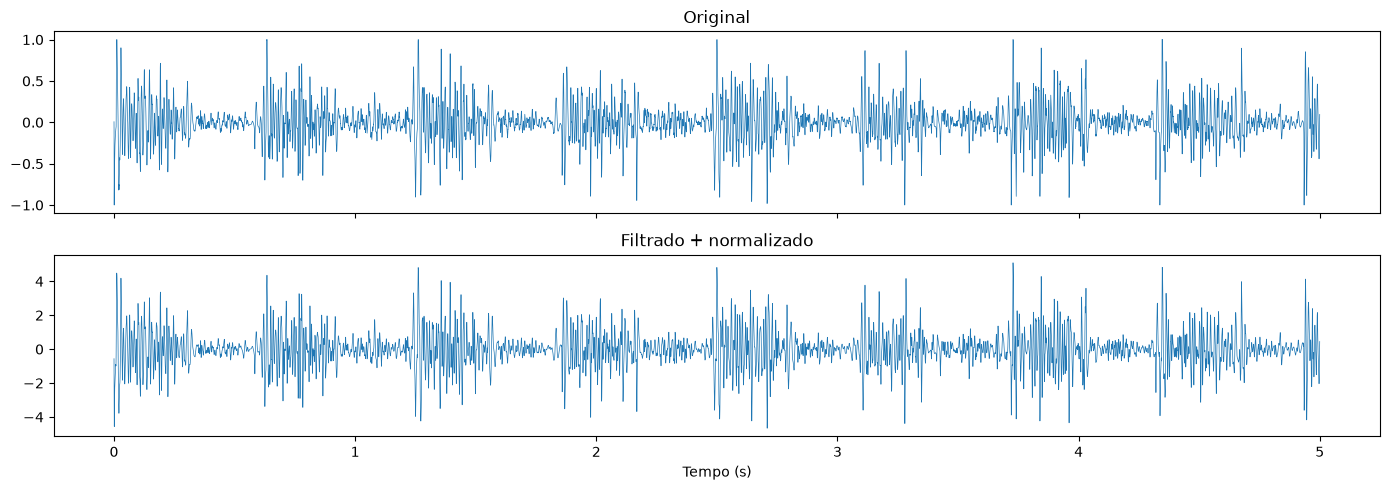

In [33]:
y_raw, _ = librosa.load(ex_forte["path"], sr=SR, duration=WINDOW_SEC)
y_clean = load_clean(ex_forte["path"])[: WINDOW_SEC * SR]

fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
t = np.arange(len(y_raw)) / SR
axes[0].plot(t, y_raw, linewidth=0.5);   axes[0].set_title("Original")
axes[1].plot(t, y_clean, linewidth=0.5); axes[1].set_title("Filtrado + normalizado")
axes[1].set_xlabel("Tempo (s)")
plt.tight_layout(); plt.show()

In [34]:
from IPython.display import Audio
display(Audio(y_raw, rate=SR))
display(Audio(y_clean, rate=SR))

### 4.3 Divisão em janelas

Os modelos exigem inputs de tamanho fixo, mas as gravações têm durações entre 5,2 s e 64,5 s. Cada gravação é dividida em janelas de 5 s com sobreposição de 50 % (passo de 2,5 s). Cada janela é um exemplo e herda a label da gravação (`label_rec`).

A sobreposição aumenta o número de exemplos de treino e garante que cada ciclo cardíaco aparece completo em pelo menos uma janela. Na avaliação, as previsões das janelas são agregadas por gravação e depois por paciente.

In [35]:
HOP_SEC = 2.5       # passo entre janelas, em segundos (50 % de sobreposição)

WIN = WINDOW_SEC * SR          # 20000 amostras
HOP = int(HOP_SEC * SR)        # 10000 amostras

def make_windows(y):
    janelas = []
    for start in range(0, len(y) - WIN + 1, HOP):
        janelas.append(y[start : start + WIN])
    return np.stack(janelas)

In [36]:
w = make_windows(load_clean(ex_forte["path"]))
print(w.shape, ex_forte["duration"])

(8, 20000) 22.896


In [37]:
rec["n_windows"] = ((rec["duration"] * SR - WIN) // HOP + 1).astype(int)

rec["n_windows"].sum()

np.int64(24198)

In [38]:
pd.crosstab(rec["split"], rec["label_rec"], values=rec["n_windows"], aggfunc="sum")

label_rec,Absent,Present,Unknown
split,,,
test,2937,494,142
train,13522,2704,842
val,2773,607,177


**Número de janelas por conjunto e classe:**

| | Absent | Present | Unknown | Total |
|---|---:|---:|---:|---:|
| Treino | 13 522 | 2 704 | 842 | 17 068 |
| Validação | 2 773 | 607 | 177 | 3 557 |
| Teste | 2 937 | 494 | 142 | 3 573 |
| **Total** | | | | **24 198** |

**Observações:**
- No treino há cerca de 5 janelas Absent por cada Present e 16 por cada Unknown, o que confirma a necessidade de compensar o desequilíbrio entre classes.
- As amostras finais de cada gravação que não completam uma janela (no máximo 2,5 s) são descartadas. Como o padrão cardíaco se repete em todos os ciclos, esta perda não é relevante.

**Armazenamento dos dados:** guardar todas as janelas ocuparia cerca de 1,9 GB e, com 50 % de sobreposição, cada amostra ficaria guardada duas vezes. Em alternativa:
- cada gravação é processada (filtrada e normalizada) uma única vez e guardada inteira (≈ 1,1 GB);
- é criada uma tabela de janelas, com uma linha por janela (gravação, amostra de início, label e conjunto);
- as janelas são extraídas no momento em que são necessárias, cortando o sinal da gravação.

Desta forma não há duplicação de dados, e alterar o tamanho da janela ou o passo exige apenas reconstruir a tabela de janelas, sem voltar a processar o áudio.

#### Processamento e armazenamento das gravações

Todas as gravações são carregadas, filtradas e normalizadas com a função `load_clean` e guardadas em disco (`signals.pkl`), numa lista em que a posição de cada sinal corresponde à linha da tabela `rec`. Nas execuções seguintes, os sinais são carregados diretamente do ficheiro, evitando repetir o processamento.

In [39]:
import pickle
from tqdm.auto import tqdm

SIGNALS_PATH = "signals.pkl"

if os.path.exists(SIGNALS_PATH):
    with open(SIGNALS_PATH, "rb") as f:
        signals = pickle.load(f)
    print("Sinais carregados do disco.")
else:
    signals = [load_clean(p) for p in tqdm(rec["path"])]
    with open(SIGNALS_PATH, "wb") as f:
        pickle.dump(signals, f)
    print("Sinais processados e guardados.")

print(len(signals), "gravações")

Sinais carregados do disco.
3163 gravações


In [40]:
i = 0
print(rec.loc[i, "path"], rec.loc[i, "duration"], len(signals[i]) / SR)

circor/training_data/13918_AV.wav 10.288 10.288


#### Tabela de janelas

Cada linha corresponde a uma janela de 5 s e guarda a gravação de origem (índice na tabela `rec`), a amostra de início, o paciente, a label e o conjunto. Esta tabela é a base do Dataset usado no treino dos modelos.

In [41]:
linhas = []

for i, row in rec.iterrows():
    n = len(signals[i])
    for start in range(0, n - WIN + 1, HOP):
        linhas.append({
            "rec_idx": i,
            "start": start,
            "patient_id": row["patient_id"],
            "label": row["label_rec"],
            "split": row["split"],
        })

windows = pd.DataFrame(linhas)
print(windows.shape)
windows.head()

(24198, 5)


,rec_idx,start,patient_id,label,split
0,0,0,13918,Absent,train
1,0,10000,13918,Absent,train
2,0,20000,13918,Absent,train
3,1,0,13918,Absent,train
4,1,10000,13918,Absent,train


In [46]:
pd.crosstab(windows["split"], windows["label"], margins=True)

label,Absent,Present,Unknown,All
split,,,,
test,2937,494,142,3573
train,13522,2704,842,17068
val,2773,607,177,3557
All,19232,3805,1161,24198


In [47]:
windows.to_csv("windows.csv", index=False)

A tabela de janelas tem 24 198 janelas, o mesmo número estimado a partir das durações, o que confirma a consistência entre a tabela de gravações e os sinais processados. A distribuição por conjunto e classe é a apresentada acima.

### 4.4 Escolha dos modelos e extração de features

Foram escolhidos dois modelos que representam o som de formas diferentes:

- **CNN (rede convolucional)** com o **espectrograma mel** de cada janela como input. Na análise exploratória, o sopro aparece como regiões de energia em posições características da representação tempo-frequência, um padrão local que as convoluções estão preparadas para detetar.
- **RNN (GRU)** com a **sequência de MFCCs** de cada janela como input. O que distingue o sopro do ruído é a sua repetição ao longo do tempo, sincronizada com o ciclo cardíaco. A RNN processa o sinal passo a passo e consegue modelar essa dependência temporal.

Os MFCCs (Mel-Frequency Cepstral Coefficients) resumem o espectro mel de cada instante em poucos coeficientes que descrevem a sua forma, o que dá uma representação mais compacta, adequada a uma sequência de entrada para a RNN.

Ambas as representações usam os mesmos parâmetros de análise: janelas de FFT de 512 amostras (≈ 128 ms), avanço de 128 amostras (≈ 32 ms) e frequências até 800 Hz.

In [48]:
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
N_MFCC = 20
FMAX = 800

In [49]:
def to_mel(w):
    S = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
                                       n_mels=N_MELS, fmax=FMAX)
    return librosa.power_to_db(S, ref=np.max).astype(np.float32)

def to_mfcc(w):
    M = librosa.feature.mfcc(y=w, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH,
                             n_mels=N_MELS, fmax=FMAX)
    return M.T.astype(np.float32)

In [50]:
rec_idx, start = windows.loc[0, ["rec_idx", "start"]]
w = signals[rec_idx][start : start + WIN]
print(to_mel(w).shape, to_mfcc(w).shape)

(64, 157) (157, 20)


### 4.5 Dataset

O Dataset do PyTorch liga a tabela de janelas aos modelos: para cada janela, extrai o excerto correspondente do sinal processado, calcula a representação de input (espectrograma mel para a CNN, MFCCs para a RNN) e devolve-a juntamente com a label codificada como inteiro (Absent = 0, Present = 1, Unknown = 2). Como a função de extração é um parâmetro, o mesmo Dataset serve para os dois modelos.

In [51]:
from torch.utils.data import Dataset, DataLoader

CLASSES = ["Absent", "Present", "Unknown"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}

class HeartDataset(Dataset):
    def __init__(self, windows_df, signals, feature_fn):
        self.df = windows_df.reset_index(drop=True)
        self.signals = signals
        self.feature_fn = feature_fn

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        w = self.signals[row["rec_idx"]][row["start"] : row["start"] + WIN]
        x = torch.from_numpy(self.feature_fn(w))
        y = LABEL2ID[row["label"]]
        return x, y

#### CNN :

In [52]:
def to_mel_cnn(w):
    return to_mel(w)[np.newaxis, :, :]     # (64, 157) → (1, 64, 157)

In [53]:
train_win = windows[windows["split"] == "train"]
ds_cnn = HeartDataset(train_win, signals, to_mel_cnn)
dl = DataLoader(ds_cnn, batch_size=32, shuffle=True)

xb, yb = next(iter(dl))
print(len(ds_cnn), xb.shape, yb.shape, yb[:10])

17068 torch.Size([32, 1, 64, 157]) torch.Size([32]) tensor([0, 0, 0, 0, 0, 1, 0, 1, 0, 0])


#### RNN :

In [56]:
ds_rnn = HeartDataset(train_win, signals, to_mfcc)
xb, yb = next(iter(DataLoader(ds_rnn, batch_size=32, shuffle=True)))
print(xb.shape)

torch.Size([32, 157, 20])
